# Dataset 1 — CU-BEMS Main Forecasting Experiment

**Project:** Reliable Multi-Horizon Smart Building Energy Demand Forecasting Using Machine Learning

This notebook implements the **primary forecasting experiment using CU-BEMS**. It is designed to complement the separate Dataset 2 environmental-ablation and Dataset 3 cross-building-generalisation notebooks.

### Main questions
1. How accurately can building electricity demand be forecast 1, 6, 12 and 24 hours ahead?
2. Do machine-learning models improve on meaningful seasonal baselines?
3. How does forecasting performance change as the horizon increases?
4. How reliable is forecasting during peak-demand periods and when sensor information is incomplete?

### Models
- Persistence
- Previous-day same-hour
- Previous-week same-hour
- Linear Regression
- LightGBM

### Evaluation
- Rolling-origin validation
- MAE
- RMSE
- R²
- nMAE
- CV(RMSE)

> **Important:** Run the notebook from top to bottom. Do not manually alter the train/test periods after results have been generated.

In [1]:
%pip install -q pandas numpy matplotlib scikit-learn lightgbm scipy

You should consider upgrading via the '/Users/daki/Desktop/SEM 2/CP/Project/Project/.venv/bin/python -m pip install --upgrade pip' command.
Note: you may need to restart the kernel to use updated packages.


In [2]:
import os
import re
import json
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

from lightgbm import LGBMRegressor

warnings.filterwarnings("ignore")

RANDOM_SEED = 42
np.random.seed(RANDOM_SEED)

pd.set_option("display.max_columns", 100)
pd.set_option("display.float_format", lambda x: f"{x:,.4f}")

## 1. Load and verify the CU-BEMS files

The CU-BEMS dataset contains separate CSV files for seven floors across 2018 and 2019. The preliminary analysis uses both years to understand the data, while the main forecasting evaluation focuses on **2019**, which provides a complete calendar year and avoids making the main evaluation depend on the shorter 2018 coverage.

In [3]:
# Locate the CU-BEMS folder.
from pathlib import Path

PROJECT_ROOT = Path.cwd().parents[1]
CU_BEMS_DIR = PROJECT_ROOT / "Dataset" / "CU-Beams"

print("CU-BEMS folder:", CU_BEMS_DIR.resolve())
print("Folder exists:", CU_BEMS_DIR.exists())

folder = CU_BEMS_DIR if CU_BEMS_DIR.exists() else None

if folder is None:
    raise FileNotFoundError(
        "CU-BEMS folder was not found. Expected a folder such as "
        "'../Dataset/CU-beams' containing the CSV files."
    )

files = sorted(folder.glob("*.csv"))

if not files:
    raise FileNotFoundError(f"No CSV files found in {folder.resolve()}")

print("CU-BEMS folder:", folder.resolve())
print("Number of CSV files:", len(files))
print("Files:")
for f in files:
    print(" -", f.name)

CU-BEMS folder: /Users/daki/Desktop/SEM 2/CP/Project/Project/Dataset/CU-Beams
Folder exists: True
CU-BEMS folder: /Users/daki/Desktop/SEM 2/CP/Project/Project/Dataset/CU-Beams
Number of CSV files: 14
Files:
 - 2018Floor1.csv
 - 2018Floor2.csv
 - 2018Floor3.csv
 - 2018Floor4.csv
 - 2018Floor5.csv
 - 2018Floor6.csv
 - 2018Floor7.csv
 - 2019Floor1.csv
 - 2019Floor2.csv
 - 2019Floor3.csv
 - 2019Floor4.csv
 - 2019Floor5.csv
 - 2019Floor6.csv
 - 2019Floor7.csv


In [4]:
# File-level verification
dataset_summary = []

for file in files:
    temp = pd.read_csv(file)

    temp["Date"] = pd.to_datetime(
        temp["Date"],
        format="mixed",
        errors="coerce"
    )

    dataset_summary.append({
        "File": file.name,
        "Rows": len(temp),
        "Columns": temp.shape[1],
        "Start": temp["Date"].min(),
        "End": temp["Date"].max(),
        "Invalid timestamps": temp["Date"].isna().sum(),
        "Duplicate timestamps": temp["Date"].duplicated().sum(),
        "Missing cells (%)": temp.isna().mean().mean() * 100,
    })

dataset_summary_df = pd.DataFrame(dataset_summary)
display(dataset_summary_df)

,File,Rows,Columns,Start,End,Invalid timestamps,Duplicate timestamps,Missing cells (%)
0,2018Floor1.csv,264960,12,2018-07-01,2018-12-31 23:59:00,0,0,1.3081
1,2018Floor2.csv,264960,37,2018-07-01,2018-12-31 23:59:00,0,0,23.1794
2,2018Floor3.csv,264960,30,2018-07-01,2018-12-31 23:59:00,0,0,38.8865
3,2018Floor4.csv,264960,30,2018-07-01,2018-12-31 23:59:00,0,0,33.0298
4,2018Floor5.csv,264960,30,2018-07-01,2018-12-31 23:59:00,0,0,26.1156
5,2018Floor6.csv,264960,30,2018-07-01,2018-12-31 23:59:00,0,0,24.7125
6,2018Floor7.csv,264960,30,2018-07-01,2018-12-31 23:59:00,0,0,24.5674
7,2019Floor1.csv,525600,12,2019-01-01,2019-12-31 23:59:00,0,0,0.1247
8,2019Floor2.csv,525600,37,2019-01-01,2019-12-31 23:59:00,0,0,6.9542
9,2019Floor3.csv,525600,30,2019-01-01,2019-12-31 23:59:00,0,0,10.7097


### 1.1 Identify electricity and environmental columns

Electricity columns are identified from the CU-BEMS naming convention containing **`(kW)`**. Environmental columns are identified using the reported units for temperature, relative humidity and illuminance.

This prevents environmental variables from being accidentally included in the electricity-demand target.

In [5]:
def identify_columns(df):
    power_cols = [c for c in df.columns if "(kW)" in c]
    temp_cols = [c for c in df.columns if "(degC)" in c]
    rh_cols = [c for c in df.columns if "(RH%)" in c]
    lux_cols = [c for c in df.columns if "(lux)" in c]
    return power_cols, temp_cols, rh_cols, lux_cols

column_summary = []

for file in files:
    temp = pd.read_csv(file, nrows=5)
    power_cols, temp_cols, rh_cols, lux_cols = identify_columns(temp)

    column_summary.append({
        "File": file.name,
        "Power columns": len(power_cols),
        "Temperature columns": len(temp_cols),
        "Humidity columns": len(rh_cols),
        "Lux columns": len(lux_cols),
    })

column_summary_df = pd.DataFrame(column_summary)
display(column_summary_df)

,File,Power columns,Temperature columns,Humidity columns,Lux columns
0,2018Floor1.csv,11,0,0,0
1,2018Floor2.csv,24,4,4,4
2,2018Floor3.csv,17,4,4,4
3,2018Floor4.csv,17,4,4,4
4,2018Floor5.csv,17,4,4,4
5,2018Floor6.csv,17,4,4,4
6,2018Floor7.csv,17,4,4,4
7,2019Floor1.csv,11,0,0,0
8,2019Floor2.csv,24,4,4,4
9,2019Floor3.csv,17,4,4,4


## 2. Data quality and missing electricity measurements

The professor's feedback requires missing electricity readings to be handled explicitly. A missing electricity measurement is **not interpreted as zero consumption**.

For the main target construction:

1. A minute-level floor demand is calculated only when **all electricity-demand components for that floor are present**.
2. An hourly floor demand is accepted only when at least **45 valid minute-level observations** are available in that hour.
3. Building-level hourly demand is calculated only when all seven floors have a valid hourly demand value.

The 45-minute rule provides a transparent minimum of 75% within-hour coverage while avoiding artificial zeros. The resulting coverage is reported below so that the rule can be reviewed rather than hidden.

In [6]:
MIN_VALID_MINUTES_PER_HOUR = 45

floor_hourly_records = []
missing_power_records = []

for file in files:
    temp = pd.read_csv(file)

    temp["Date"] = pd.to_datetime(
        temp["Date"],
        format="mixed",
        errors="coerce"
    )
    temp = temp.dropna(subset=["Date"]).copy()
    temp = temp.sort_values("Date")

    power_cols, temp_cols, rh_cols, lux_cols = identify_columns(temp)

    if not power_cols:
        print(f"WARNING: No power columns found in {file.name}")
        continue

    # Record missingness in the raw electricity sensors.
    for col in power_cols:
        missing_power_records.append({
            "File": file.name,
            "Sensor": col,
            "Missing count": int(temp[col].isna().sum()),
            "Missing %": float(temp[col].isna().mean() * 100)
        })

    # A minute is valid for floor demand only when every power component is present.
    valid_power = temp[power_cols].notna().all(axis=1)

    temp["floor_demand"] = np.where(
        valid_power,
        temp[power_cols].sum(axis=1),
        np.nan
    )

    temp["valid_minute"] = temp["floor_demand"].notna().astype(int)

    hourly = (
        temp.set_index("Date")[["floor_demand", "valid_minute"]]
        .resample("1h")
        .agg({
            "floor_demand": "mean",
            "valid_minute": "sum"
        })
        .reset_index()
    )

    hourly["File"] = file.name
    hourly["Floor"] = re.search(r"Floor(\d+)", file.name).group(1)

    # Do not retain an hourly target created from too few valid minutes.
    hourly.loc[
        hourly["valid_minute"] < MIN_VALID_MINUTES_PER_HOUR,
        "floor_demand"
    ] = np.nan

    floor_hourly_records.append(hourly)

floor_hourly = pd.concat(floor_hourly_records, ignore_index=True)

missing_power_df = pd.DataFrame(missing_power_records)

print("Raw electricity sensors with missing values:")
display(
    missing_power_df[missing_power_df["Missing count"] > 0]
    .sort_values("Missing %", ascending=False)
    .head(30)
)

Raw electricity sensors with missing values:


,File,Sensor,Missing count,Missing %
174,2019Floor4.csv,z1_AC3(kW),134123,25.5181
173,2019Floor4.csv,z1_AC2(kW),134123,25.5181
172,2019Floor4.csv,z1_AC1(kW),134123,25.5181
37,2018Floor3.csv,z1_AC3(kW),67029,25.2978
36,2018Floor3.csv,z1_AC2(kW),67029,25.2978
35,2018Floor3.csv,z1_AC1(kW),67029,25.2978
50,2018Floor3.csv,z5_Light(kW),59758,22.5536
47,2018Floor3.csv,z4_Light(kW),59758,22.5536
38,2018Floor3.csv,z1_AC4(kW),59627,22.5042
49,2018Floor3.csv,z5_AC1(kW),59626,22.5038


In [7]:
# Hourly coverage after the explicit target-quality rule
hourly_coverage = (
    floor_hourly
    .assign(valid_hour=floor_hourly["floor_demand"].notna())
    .groupby(["File", "Floor"])
    .agg(
        hourly_rows=("Date", "size"),
        valid_hours=("valid_hour", "sum"),
        mean_valid_minutes=("valid_minute", "mean")
    )
    .reset_index()
)

hourly_coverage["valid_hour_pct"] = (
    hourly_coverage["valid_hours"] /
    hourly_coverage["hourly_rows"] * 100
)

display(hourly_coverage)

,File,Floor,hourly_rows,valid_hours,mean_valid_minutes,valid_hour_pct
0,2018Floor1.csv,1,4416,3921,53.2321,88.7908
1,2018Floor2.csv,2,4416,4407,59.8544,99.7962
2,2018Floor3.csv,3,4416,3299,44.6243,74.7056
3,2018Floor4.csv,4,4416,3580,48.0754,81.0688
4,2018Floor5.csv,5,4416,4264,57.4948,96.5580
5,2018Floor6.csv,6,4416,4401,59.1875,99.6603
6,2018Floor7.csv,7,4416,4405,59.8705,99.7509
7,2019Floor1.csv,1,8760,8747,59.8676,99.8516
8,2019Floor2.csv,2,8760,8259,56.5759,94.2808
9,2019Floor3.csv,3,8760,8035,54.8561,91.7237


## 3. Construct building-level hourly demand

The seven floors are aligned by timestamp. A building-level target is produced only when **all seven floors have valid hourly demand**.

This conservative construction avoids silently dropping a missing floor and treating the remaining floors as the complete building load.

In [8]:
# Pivot floors into columns so missing floors remain visible.
floor_wide = (
    floor_hourly
    .pivot_table(
        index="Date",
        columns="Floor",
        values="floor_demand",
        aggfunc="first"
    )
    .sort_index()
)

expected_floors = [str(i) for i in range(1, 8)]
available_floors = [f for f in expected_floors if f in floor_wide.columns]

print("Available floors:", available_floors)

if len(available_floors) != 7:
    raise ValueError(
        f"Expected seven floors, but found {len(available_floors)}: {available_floors}"
    )

floor_wide = floor_wide[expected_floors]

building_hourly = pd.DataFrame(index=floor_wide.index)
building_hourly["building_demand"] = floor_wide.sum(
    axis=1,
    min_count=7
)

building_hourly["valid_floors"] = floor_wide.notna().sum(axis=1)
building_hourly = building_hourly.reset_index()

print("Building-level hourly dataset:")
display(building_hourly.head())

Available floors: ['1', '2', '3', '4', '5', '6', '7']
Building-level hourly dataset:


,Date,building_demand,valid_floors
0,2018-07-01 00:00:00,176.2931,7
1,2018-07-01 01:00:00,177.3191,7
2,2018-07-01 02:00:00,177.0585,7
3,2018-07-01 03:00:00,175.1292,7
4,2018-07-01 04:00:00,183.1750,7


In [9]:
# Main modelling period: 2019
building_2019 = building_hourly[
    (building_hourly["Date"] >= "2019-01-01") &
    (building_hourly["Date"] < "2020-01-01")
].copy()

print("2019 date range:", building_2019["Date"].min(), "to", building_2019["Date"].max())
print("Rows:", len(building_2019))
print("Valid target hours:", building_2019["building_demand"].notna().sum())
print("Missing target hours:", building_2019["building_demand"].isna().sum())
print("Valid target percentage:",
      building_2019["building_demand"].notna().mean() * 100)

2019 date range: 2019-01-01 00:00:00 to 2019-12-31 23:00:00
Rows: 8747
Valid target hours: 4338
Missing target hours: 4409
Valid target percentage: 49.59414656453641


## 4. Aggregate environmental information

For CU-BEMS Floors 2–7, environmental sensors are aggregated to hourly values.

Only environmental information measured at **time t** is used as a predictor for a forecast originating at t. We do not use the actual environmental value at the future target time `t+h`.

Missing environmental values are retained as missing here and are handled by model pipelines using training-data-fitted imputation.

In [10]:
environment_records = []

for file in files:
    if not file.name.startswith("2019") or "Floor1" in file.name:
        continue

    temp = pd.read_csv(file)
    temp["Date"] = pd.to_datetime(
        temp["Date"],
        format="mixed",
        errors="coerce"
    )
    temp = temp.dropna(subset=["Date"]).sort_values("Date")

    power_cols, temp_cols, rh_cols, lux_cols = identify_columns(temp)

    # Floor demand follows the same strict target-quality rule.
    valid_power = temp[power_cols].notna().all(axis=1)
    temp["floor_demand"] = np.where(
        valid_power,
        temp[power_cols].sum(axis=1),
        np.nan
    )

    # Environmental variables are sensor averages at the current timestamp.
    temp["temperature"] = temp[temp_cols].mean(axis=1) if temp_cols else np.nan
    temp["humidity"] = temp[rh_cols].mean(axis=1) if rh_cols else np.nan
    temp["lux"] = temp[lux_cols].mean(axis=1) if lux_cols else np.nan

    hourly = (
        temp.set_index("Date")[
            ["floor_demand", "temperature", "humidity", "lux"]
        ]
        .resample("1h")
        .agg({
            "floor_demand": "mean",
            "temperature": "mean",
            "humidity": "mean",
            "lux": "mean"
        })
        .reset_index()
    )

    hourly["Floor"] = re.search(r"Floor(\d+)", file.name).group(1)
    environment_records.append(hourly)

environment_floor = pd.concat(environment_records, ignore_index=True)

# Building-level environmental features = mean across available Floors 2–7.
environment_building = (
    environment_floor
    .groupby("Date")[["temperature", "humidity", "lux"]]
    .mean()
    .reset_index()
)

building_2019 = building_2019.merge(
    environment_building,
    on="Date",
    how="left"
)

display(building_2019.head())

,Date,building_demand,valid_floors,temperature,humidity,lux
0,2019-01-01 00:00:00,97.2477,7,NaN,NaN,NaN
1,2019-01-01 01:00:00,98.3710,7,NaN,NaN,NaN
2,2019-01-01 02:00:00,90.9457,7,NaN,NaN,NaN
3,2019-01-01 03:00:00,85.5285,7,NaN,NaN,NaN
4,2019-01-01 04:00:00,96.4230,7,NaN,NaN,NaN


## 5. Forecasting features

Features are constructed only from information available at the forecasting origin.

### Historical demand
- 1, 2, 3, 6, 12, 24, 48 and 168-hour lags

### Rolling statistics
- 24-hour mean/std/min/max
- 168-hour mean/std/min/max

### Time information
- hour
- day of week
- weekend
- day of month
- month

Environmental variables are current-time features only. Future environmental measurements are not included.

In [11]:
def add_features(df):
    out = df.copy().sort_values("Date").reset_index(drop=True)

    # Historical demand features
    lag_hours = [1, 2, 3, 6, 12, 24, 48, 168]
    for lag in lag_hours:
        out[f"lag_{lag}h"] = out["building_demand"].shift(lag)

    # Rolling features use only past observations by shifting first.
    shifted = out["building_demand"].shift(1)

    for window in [24, 168]:
        out[f"rolling_mean_{window}h"] = shifted.rolling(window).mean()
        out[f"rolling_std_{window}h"] = shifted.rolling(window).std()
        out[f"rolling_min_{window}h"] = shifted.rolling(window).min()
        out[f"rolling_max_{window}h"] = shifted.rolling(window).max()

    # Calendar features
    out["hour"] = out["Date"].dt.hour
    out["day_of_week"] = out["Date"].dt.dayofweek
    out["is_weekend"] = (out["day_of_week"] >= 5).astype(int)
    out["day_of_month"] = out["Date"].dt.day
    out["month"] = out["Date"].dt.month

    return out

featured = add_features(building_2019)

display(featured.head())

,Date,building_demand,valid_floors,temperature,humidity,lux,lag_1h,lag_2h,lag_3h,lag_6h,lag_12h,lag_24h,lag_48h,lag_168h,rolling_mean_24h,rolling_std_24h,rolling_min_24h,rolling_max_24h,rolling_mean_168h,rolling_std_168h,rolling_min_168h,rolling_max_168h,hour,day_of_week,is_weekend,day_of_month,month
0,2019-01-01 00:00:00,97.2477,7,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0,1,0,1,1
1,2019-01-01 01:00:00,98.3710,7,NaN,NaN,NaN,97.2477,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,1,1,0,1,1
2,2019-01-01 02:00:00,90.9457,7,NaN,NaN,NaN,98.3710,97.2477,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,2,1,0,1,1
3,2019-01-01 03:00:00,85.5285,7,NaN,NaN,NaN,90.9457,98.3710,97.2477,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,3,1,0,1,1
4,2019-01-01 04:00:00,96.4230,7,NaN,NaN,NaN,85.5285,90.9457,98.3710,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,4,1,0,1,1


## 6. Forecasting targets

For each forecasting horizon, the target is the building demand at:

- `t + 1 hour`
- `t + 6 hours`
- `t + 12 hours`
- `t + 24 hours`

The predictors remain anchored at time `t`.

In [12]:
HORIZONS = [1, 6, 12, 24]

# Create future forecasting targets
for h in HORIZONS:
    featured[f"target_{h}h"] = featured["building_demand"].shift(-h)

# Final modelling dataset
# Keep all observations here; missing targets/features will be handled
# separately inside the validation and model-fitting process.
model_data = featured.copy()

print("Forecast targets created:")
display(
    model_data[
        ["Date", "building_demand"] +
        [f"target_{h}h" for h in HORIZONS]
    ].head(30)
)

print("\nModel dataset shape:", model_data.shape)

Forecast targets created:


,Date,building_demand,target_1h,target_6h,target_12h,target_24h
0,2019-01-01 00:00:00,97.2477,98.3710,77.0857,74.6158,101.2200
1,2019-01-01 01:00:00,98.3710,90.9457,70.5713,74.3820,104.2695
2,2019-01-01 02:00:00,90.9457,85.5285,73.0145,77.8779,101.9550
3,2019-01-01 03:00:00,85.5285,96.4230,71.4417,76.9669,102.2843
4,2019-01-01 04:00:00,96.4230,99.5567,84.3278,86.3096,113.9920
5,2019-01-01 05:00:00,99.5567,77.0857,77.0054,93.1240,123.3378
6,2019-01-01 06:00:00,77.0857,70.5713,74.6158,117.5310,125.6948
7,2019-01-01 07:00:00,70.5713,73.0145,74.3820,123.4113,219.0252
8,2019-01-01 08:00:00,73.0145,71.4417,77.8779,144.1697,573.1600
9,2019-01-01 09:00:00,71.4417,84.3278,76.9669,119.4930,523.5605



Model dataset shape: (8747, 31)


## 7. Leakage checks

This section verifies that no feature uses the future target.

The lag and rolling features are explicitly shifted backward. Environmental variables are measured at time `t`, not `t+h`.

The final modelling features therefore represent information that can be known at the forecasting origin.

In [13]:
feature_cols = [
    "lag_1h", "lag_2h", "lag_3h", "lag_6h",
    "lag_12h", "lag_24h", "lag_48h", "lag_168h",
    "rolling_mean_24h", "rolling_std_24h",
    "rolling_min_24h", "rolling_max_24h",
    "rolling_mean_168h", "rolling_std_168h",
    "rolling_min_168h", "rolling_max_168h",
    "hour", "day_of_week", "is_weekend",
    "day_of_month", "month",
    "temperature", "humidity", "lux"
]

assert not any(
    re.search(r"target_\d+h", c) for c in feature_cols
), "Future target accidentally included in features."

print("Number of features:", len(feature_cols))
print("Features:")
print(feature_cols)

Number of features: 24
Features:
['lag_1h', 'lag_2h', 'lag_3h', 'lag_6h', 'lag_12h', 'lag_24h', 'lag_48h', 'lag_168h', 'rolling_mean_24h', 'rolling_std_24h', 'rolling_min_24h', 'rolling_max_24h', 'rolling_mean_168h', 'rolling_std_168h', 'rolling_min_168h', 'rolling_max_168h', 'hour', 'day_of_week', 'is_weekend', 'day_of_month', 'month', 'temperature', 'humidity', 'lux']


## 8. Rolling-origin validation design

To maintain chronological order, no random train-test split is used.

The main evaluation uses **six two-week test folds**, beginning on **1 March 2019**. For each fold:

- Training data = observations before the test fold
- Test data = the next two weeks
- The forecasting origin moves forward for the next fold

The same folds are used for every model and forecasting horizon.

In [14]:
FOLD_START = pd.Timestamp("2019-06-01")
FOLD_LENGTH_DAYS = 14
N_FOLDS = 6

folds = []

for fold in range(N_FOLDS):
    test_start = FOLD_START + pd.Timedelta(days=FOLD_LENGTH_DAYS * fold)
    test_end = test_start + pd.Timedelta(days=FOLD_LENGTH_DAYS)

    folds.append({
        "fold": fold + 1,
        "test_start": test_start,
        "test_end": test_end
    })

fold_df = pd.DataFrame(folds)
display(fold_df)

,fold,test_start,test_end
0,1,2019-06-01,2019-06-15
1,2,2019-06-15,2019-06-29
2,3,2019-06-29,2019-07-13
3,4,2019-07-13,2019-07-27
4,5,2019-07-27,2019-08-10
5,6,2019-08-10,2019-08-24


## 9. Model definitions

### Seasonal baselines
1. Persistence — most recent observed demand
2. Previous-day — demand at `t-24h`
3. Previous-week — demand at `t-168h`

### Machine-learning models
- Linear Regression with training-fitted median imputation and scaling
- LightGBM using the same core configuration used in the supporting notebooks

The model implementations are deterministic using seed 42 where applicable.

In [15]:
def persistence_prediction(history, n):
    if len(history) == 0:
        return np.full(n, np.nan)
    return np.repeat(history.iloc[-1], n)

def seasonal_prediction(train_series, test_dates, lag_hours):
    # Lookup the value lag_hours before each forecast origin.
    lookup = train_series.copy()
    return test_dates.map(
        lookup.shift(lag_hours)
    )

# For seasonal baselines we will use the complete chronological series
# and shift by the required number of hours. These values must exist before t.

In [16]:
lr_model = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler()),
    ("model", LinearRegression())
])

def make_lgbm():
    return LGBMRegressor(
        n_estimators=600,
        learning_rate=0.03,
        num_leaves=31,
        random_state=RANDOM_SEED,
        verbosity=-1
    )

## 10. Evaluation functions

In addition to MAE, RMSE and R², we calculate:

**nMAE (%)**

`MAE / mean(actual) × 100`

**CV(RMSE) (%)**

`RMSE / mean(actual) × 100`

These scale-free measures are useful for comparing forecasting errors across different datasets or demand scales.

In [17]:
def regression_metrics(y_true, y_pred):
    """
    Calculate forecasting regression metrics.

    Both actual and predicted values are converted to NumPy arrays
    so that metrics are calculated positionally rather than by index.
    """

    y_true = np.asarray(y_true, dtype=float)
    y_pred = np.asarray(y_pred, dtype=float)

    # Keep only observations where both actual and predicted values exist
    valid = np.isfinite(y_true) & np.isfinite(y_pred)

    y_true = y_true[valid]
    y_pred = y_pred[valid]

    if len(y_true) == 0:
        return {
            "n": 0,
            "MAE": np.nan,
            "RMSE": np.nan,
            "R2": np.nan,
            "nMAE (%)": np.nan,
            "CV(RMSE) (%)": np.nan
        }

    mae = mean_absolute_error(y_true, y_pred)
    rmse = np.sqrt(mean_squared_error(y_true, y_pred))

    r2 = (
        r2_score(y_true, y_pred)
        if len(y_true) > 1
        else np.nan
    )

    mean_actual = np.mean(y_true)

    return {
        "n": len(y_true),
        "MAE": mae,
        "RMSE": rmse,
        "R2": r2,
        "nMAE (%)": (
            mae / mean_actual * 100
            if mean_actual != 0
            else np.nan
        ),
        "CV(RMSE) (%)": (
            rmse / mean_actual * 100
            if mean_actual != 0
            else np.nan
        )
    }

## 11. Run rolling-origin forecasting experiment

Each horizon is evaluated separately. This avoids mixing targets from different horizons.

For machine-learning models, the model is fitted only on training observations before the test fold.

For seasonal baselines, predictions are generated from historical demand values that occur before the forecasting origin.

All models are scored on the same valid test timestamps for each fold.

In [18]:
# Final modelling dataset used by all forecasting experiments
model_data = featured.copy()

print("model_data shape:", model_data.shape)
print("Columns:")
print(model_data.columns.tolist())

model_data shape: (8747, 31)
Columns:
['Date', 'building_demand', 'valid_floors', 'temperature', 'humidity', 'lux', 'lag_1h', 'lag_2h', 'lag_3h', 'lag_6h', 'lag_12h', 'lag_24h', 'lag_48h', 'lag_168h', 'rolling_mean_24h', 'rolling_std_24h', 'rolling_min_24h', 'rolling_max_24h', 'rolling_mean_168h', 'rolling_std_168h', 'rolling_min_168h', 'rolling_max_168h', 'hour', 'day_of_week', 'is_weekend', 'day_of_month', 'month', 'target_1h', 'target_6h', 'target_12h', 'target_24h']


In [19]:
# Run the full rolling-origin experiment.
results_by_fold = []
predictions = []

# Complete chronological demand series for seasonal baseline lookups
demand_series = model_data.set_index("Date")["building_demand"].sort_index()

for h in HORIZONS:
    target_col = f"target_{h}h"

    # Reference lags for the target timestamp:
    # previous-day: target time - 24h
    # previous-week: target time - 168h
    previous_day_lag = 24 - h
    previous_week_lag = 168 - h

    for fold_info in folds:
        fold = fold_info["fold"]
        test_start = fold_info["test_start"]
        test_end = fold_info["test_end"]

        # Training target must finish before the test fold.
        train_mask = (
            (model_data["Date"] + pd.Timedelta(hours=h)) < test_start
        )

        test_mask = (
            (model_data["Date"] >= test_start) &
            (model_data["Date"] < test_end)
        )

        train = model_data.loc[train_mask].copy()
        test = model_data.loc[test_mask].copy()

        train = train.dropna(subset=[target_col])
        test = test.dropna(subset=[target_col])

        if len(train) == 0 or len(test) == 0:
            continue

        y_train = train[target_col]
        y_test = test[target_col]

        # Identify missing environmental information in the test period.
        env_cols_present = [
            c for c in ["temperature", "humidity", "lux"]
            if c in test.columns
        ]

        if env_cols_present:
            test_env_missing = test[env_cols_present].isna().any(axis=1)
        else:
            test_env_missing = pd.Series(False, index=test.index)

        # ---------------------------------------------------------
        # Baseline predictions
        # ---------------------------------------------------------

        # Persistence:
        # Predict the target using demand observed at the forecast origin.
        pred_persistence = test["building_demand"]

        # Previous-day:
        # Target is t+h, so previous-day reference is t+h-24.
        previous_day_dates = (
            test["Date"] +
            pd.Timedelta(hours=h - 24)
        )

        pred_previous_day = previous_day_dates.map(demand_series)

        # Previous-week:
        # Target is t+h, so previous-week reference is t+h-168.
        previous_week_dates = (
            test["Date"] +
            pd.Timedelta(hours=h - 168)
        )

        pred_previous_week = previous_week_dates.map(demand_series)

        baseline_predictions = {
            "Persistence": pred_persistence,
            "Previous-day": pred_previous_day,
            "Previous-week": pred_previous_week
        }

        for method, pred in baseline_predictions.items():

            metrics = regression_metrics(y_test, pred)

            results_by_fold.append({
                "Model": method,
                "Horizon": h,
                "Fold": fold,
                "Test start": test_start,
                "Test end": test_end,
                **metrics
            })

            p = test[["Date"]].copy()
            p["Model"] = method
            p["Horizon"] = h
            p["Fold"] = fold
            p["Actual"] = y_test.values
            p["Predicted"] = pred.values
            p["Environmental information missing"] = test_env_missing.values

            predictions.append(p)

        # ---------------------------------------------------------
        # Linear Regression
        # ---------------------------------------------------------

        model_features = [
            c for c in feature_cols
            if c in train.columns
        ]

        lr_fit = lr_model.fit(
            train[model_features],
            y_train
        )

        pred_lr = lr_fit.predict(
            test[model_features]
        )

        metrics = regression_metrics(
            y_test,
            pred_lr
        )

        results_by_fold.append({
            "Model": "Linear Regression",
            "Horizon": h,
            "Fold": fold,
            "Test start": test_start,
            "Test end": test_end,
            **metrics
        })

        p = test[["Date"]].copy()
        p["Model"] = "Linear Regression"
        p["Horizon"] = h
        p["Fold"] = fold
        p["Actual"] = y_test.values
        p["Predicted"] = pred_lr
        p["Environmental information missing"] = test_env_missing.values

        predictions.append(p)

        # ---------------------------------------------------------
        # LightGBM
        # ---------------------------------------------------------

        lgbm = make_lgbm()

        lgbm.fit(
            train[model_features],
            y_train
        )

        pred_lgbm = lgbm.predict(
            test[model_features]
        )

        metrics = regression_metrics(
            y_test,
            pred_lgbm
        )

        results_by_fold.append({
            "Model": "LightGBM",
            "Horizon": h,
            "Fold": fold,
            "Test start": test_start,
            "Test end": test_end,
            **metrics
        })

        p = test[["Date"]].copy()
        p["Model"] = "LightGBM"
        p["Horizon"] = h
        p["Fold"] = fold
        p["Actual"] = y_test.values
        p["Predicted"] = pred_lgbm
        p["Environmental information missing"] = test_env_missing.values

        predictions.append(p)


# Convert results to DataFrames
results_by_fold = pd.DataFrame(results_by_fold)
predictions_df = pd.concat(
    predictions,
    ignore_index=True
)

display(results_by_fold.head())

print("Rows of results:", len(results_by_fold))

,Model,Horizon,Fold,Test start,Test end,n,MAE,RMSE,R2,nMAE (%),CV(RMSE) (%)
0,Persistence,1,1,2019-06-01,2019-06-15,336,62.6533,125.4694,0.6051,23.3791,46.8190
1,Previous-day,1,1,2019-06-01,2019-06-15,336,84.7016,163.5238,0.3293,31.6065,61.0191
2,Previous-week,1,1,2019-06-01,2019-06-15,276,63.4964,125.3060,0.6449,21.5280,42.4841
3,Linear Regression,1,1,2019-06-01,2019-06-15,336,131.0482,171.7530,0.2601,48.9007,64.0898
4,LightGBM,1,1,2019-06-01,2019-06-15,336,48.6448,69.9555,0.8772,18.1519,26.1040


Rows of results: 120


## 12. Overall model comparison

The table below averages the fold-level metrics for each model and horizon.

The mean values should be interpreted together with the fold-level results because averaging alone can hide instability between validation folds.

In [20]:
summary_results = (
    results_by_fold
    .groupby(["Model", "Horizon"])
    .agg(
        folds=("Fold", "nunique"),
        n=("n", "mean"),
        MAE=("MAE", "mean"),
        RMSE=("RMSE", "mean"),
        R2=("R2", "mean"),
        nMAE=("nMAE (%)", "mean"),
        CV_RMSE=("CV(RMSE) (%)", "mean")
    )
    .reset_index()
    .sort_values(["Horizon", "RMSE"])
)

display(summary_results)

,Model,Horizon,folds,n,MAE,RMSE,R2,nMAE,CV_RMSE
0,LightGBM,1,6,335.0000,36.4203,52.3546,0.9235,14.0945,20.2315
16,Previous-week,1,6,324.0000,60.1051,109.8230,0.6442,23.0719,42.2562
8,Persistence,1,6,335.0000,62.0749,124.8851,0.5787,24.0675,48.4513
4,Linear Regression,1,6,335.0000,95.0602,126.2108,0.5656,36.7811,48.8398
12,Previous-day,1,6,334.0000,86.3589,161.7605,0.2972,33.5351,62.7701
1,LightGBM,6,6,335.0000,48.4683,83.0280,0.8017,18.8436,32.4089
17,Previous-week,6,6,324.8333,60.0680,109.7147,0.6447,23.1049,42.3054
5,Linear Regression,6,6,335.0000,105.3420,135.1113,0.5068,40.9052,52.5003
13,Previous-day,6,6,334.0000,85.9493,161.3375,0.3017,33.3835,62.6227
9,Persistence,6,6,335.0000,157.4797,232.7619,-0.4573,61.0888,90.3278


In [21]:
# Compact comparison table: CV(RMSE) by model and horizon
comparison_cvrmse = (
    summary_results
    .pivot(index="Model", columns="Horizon", values="CV_RMSE")
    .rename(columns=lambda x: f"{x}h")
)

display(comparison_cvrmse.round(2))

Horizon,1h,6h,12h,24h
Model,,,,
LightGBM,20.2300,32.4100,40.4700,40.8400
Linear Regression,48.8400,52.5000,58.8500,71.4800
Persistence,48.4500,90.3300,121.0300,62.7500
Previous-day,62.7700,62.6200,62.4500,62.7500
Previous-week,42.2600,42.3100,42.4500,42.5900


## 13. Fold-to-fold stability

Reliability should not be judged only from one average score. We therefore inspect how much the error varies between rolling-origin folds.

In [22]:
fold_stability = (
    results_by_fold
    .groupby(["Model", "Horizon"])
    .agg(
        RMSE_mean=("RMSE", "mean"),
        RMSE_std=("RMSE", "std"),
        CV_RMSE_mean=("CV(RMSE) (%)", "mean"),
        CV_RMSE_std=("CV(RMSE) (%)", "std")
    )
    .reset_index()
)

display(fold_stability.round(3))

,Model,Horizon,RMSE_mean,RMSE_std,CV_RMSE_mean,CV_RMSE_std
0,LightGBM,1,52.3550,12.1160,20.2320,4.2920
1,LightGBM,6,83.0280,29.3560,32.4090,12.1330
2,LightGBM,12,103.7710,36.4070,40.4670,14.4730
3,LightGBM,24,105.0400,20.6590,40.8420,8.8070
4,Linear Regression,1,126.2110,24.2900,48.8400,8.5370
5,Linear Regression,6,135.1110,25.6860,52.5000,10.5030
6,Linear Regression,12,151.7750,48.8010,58.8490,18.3910
7,Linear Regression,24,185.4560,91.9410,71.4840,33.6040
8,Persistence,1,124.8850,2.9700,48.4510,1.9520
9,Persistence,6,232.7620,10.4500,90.3280,4.7890


## 14. Peak-demand reliability

Peak demand is defined separately within the evaluated 2019 target period using the **90th percentile of observed building demand**.

The experiment compares forecasting error during peak-demand observations with the overall error. The purpose is to determine whether a model remains reliable when electricity demand is unusually high.

In [23]:
print(predictions_df.columns.tolist())

['Date', 'Model', 'Horizon', 'Fold', 'Actual', 'Predicted', 'Environmental information missing']


In [24]:
# Peak-demand evaluation
# Peak threshold is calculated from training observations separately for each fold
# to avoid using future test-period information to define "peak".

peak_predictions = []

for h in HORIZONS:
    target_col = f"target_{h}h"

    for fold_info in folds:
        fold = fold_info["fold"]
        test_start = fold_info["test_start"]
        test_end = fold_info["test_end"]

        train_mask = (
            (model_data["Date"] + pd.Timedelta(hours=h)) < test_start
        )

        test_mask = (
            (model_data["Date"] >= test_start) &
            (model_data["Date"] < test_end)
        )

        train_targets = model_data.loc[
            train_mask, target_col
        ].dropna()

        if train_targets.empty:
            continue

        peak_threshold = train_targets.quantile(0.90)

        subset = predictions_df[
            (predictions_df["Horizon"] == h) &
            (predictions_df["Fold"] == fold)
        ].copy()

        if subset.empty:
            continue

        subset["Peak"] = subset["Actual"] >= peak_threshold
        subset["Peak threshold"] = peak_threshold

        peak_predictions.append(subset)


# Combine peak observations
if peak_predictions:
    peak_predictions = pd.concat(
        peak_predictions,
        ignore_index=True
    )
else:
    peak_predictions = pd.DataFrame()


# Calculate peak-demand metrics
peak_summary = []

if not peak_predictions.empty:

    for (model, horizon), group in peak_predictions.groupby(
        ["Model", "Horizon"]
    ):
        peak_group = group[group["Peak"]]

        if len(peak_group) == 0:
            continue

        metrics = regression_metrics(
            peak_group["Actual"],
            peak_group["Predicted"]
        )

        peak_summary.append({
            "Model": model,
            "Horizon": horizon,
            **metrics
        })


# Display results safely
if peak_summary:

    peak_summary = pd.DataFrame(peak_summary)

    display(
        peak_summary
        .sort_values(["Horizon", "RMSE"])
        .round(3)
    )

else:

    peak_summary = pd.DataFrame(
        columns=[
            "Model",
            "Horizon",
            "n",
            "MAE",
            "RMSE",
            "R2",
            "nMAE (%)",
            "CV(RMSE) (%)"
        ]
    )

    print("No valid peak-demand observations were available for the current folds.")

,Model,Horizon,n,MAE,RMSE,R2,nMAE (%),CV(RMSE) (%)
0,LightGBM,1,247,45.1000,63.5880,-0.4230,6.8120,9.6050
4,Linear Regression,1,247,163.6550,190.4850,-11.7740,24.7190,28.7720
16,Previous-week,1,247,119.3360,208.2040,-14.2610,18.0250,31.4480
8,Persistence,1,247,200.8200,283.7670,-27.3480,30.3330,42.8610
12,Previous-day,1,247,206.2850,323.6060,-35.8670,31.1580,48.8790
1,LightGBM,6,247,71.9560,105.2610,-2.9010,10.8690,15.8990
5,Linear Regression,6,247,171.3980,190.6530,-11.7960,25.8890,28.7970
17,Previous-week,6,247,119.3360,208.2040,-14.2610,18.0250,31.4480
13,Previous-day,6,247,206.2850,323.6060,-35.8670,31.1580,48.8790
9,Persistence,6,247,384.6600,440.4610,-67.2990,58.1010,66.5290


In [25]:
# Compare peak CV(RMSE) with overall CV(RMSE)
overall_peak_comparison = peak_summary.merge(
    summary_results[["Model", "Horizon", "CV_RMSE"]],
    on=["Model", "Horizon"],
    how="left"
).rename(columns={"CV_RMSE": "Overall CV(RMSE) (%)"})

overall_peak_comparison["Peak - Overall CV(RMSE)"] = (
    overall_peak_comparison["CV(RMSE) (%)"] -
    overall_peak_comparison["Overall CV(RMSE) (%)"]
)

display(
    overall_peak_comparison[
        ["Model", "Horizon", "CV(RMSE) (%)",
         "Overall CV(RMSE) (%)", "Peak - Overall CV(RMSE)"]
    ].sort_values(["Horizon", "CV(RMSE) (%)"]).round(3)
)

,Model,Horizon,CV(RMSE) (%),Overall CV(RMSE) (%),Peak - Overall CV(RMSE)
0,LightGBM,1,9.6050,20.2320,-10.6270
4,Linear Regression,1,28.7720,48.8400,-20.0680
16,Previous-week,1,31.4480,42.2560,-10.8080
8,Persistence,1,42.8610,48.4510,-5.5900
12,Previous-day,1,48.8790,62.7700,-13.8910
1,LightGBM,6,15.8990,32.4090,-16.5100
5,Linear Regression,6,28.7970,52.5000,-23.7030
17,Previous-week,6,31.4480,42.3050,-10.8570
13,Previous-day,6,48.8790,62.6230,-13.7440
9,Persistence,6,66.5290,90.3280,-23.7990


## 16. Missing-environment robustness

Because CU-BEMS environmental sensors contain missing values, we compare prediction error on test observations with complete environmental information versus observations where at least one environmental variable is missing.

The models use training-fitted median imputation, so this experiment tests whether prediction reliability changes when environmental input information is incomplete.

In [26]:
missing_env_results = []

for (model, horizon), group in predictions_df.groupby(["Model", "Horizon"]):
    for condition, subset in group.groupby("Environmental information missing"):
        m = regression_metrics(subset["Actual"], subset["Predicted"])

        missing_env_results.append({
            "Model": model,
            "Horizon": horizon,
            "Environmental information": (
                "Missing ≥1 environmental variable"
                if condition else
                "Complete environmental variables"
            ),
            **m
        })

missing_env_summary = pd.DataFrame(missing_env_results)

display(
    missing_env_summary
    .sort_values(["Horizon", "Model", "Environmental information"])
    .round(3)
)

,Model,Horizon,Environmental information,n,MAE,RMSE,R2,nMAE (%),CV(RMSE) (%)
0,LightGBM,1,Complete environmental variables,2010,36.4110,53.4990,0.9240,14.1100,20.7320
4,Linear Regression,1,Complete environmental variables,2010,95.0670,128.1490,0.5610,36.8400,49.6600
8,Persistence,1,Complete environmental variables,2010,62.0760,124.9090,0.5830,24.0560,48.4050
12,Previous-day,1,Complete environmental variables,2004,86.2130,163.6690,0.2850,33.3530,63.3180
16,Previous-week,1,Complete environmental variables,1944,59.8430,118.0980,0.6350,22.8480,45.0900
1,LightGBM,6,Complete environmental variables,2010,48.4430,87.1360,0.7970,18.7800,33.7800
5,Linear Regression,6,Complete environmental variables,2010,105.3180,137.0780,0.4980,40.8280,53.1410
9,Persistence,6,Complete environmental variables,2010,157.4790,232.9410,-0.4490,61.0490,90.3040
13,Previous-day,6,Complete environmental variables,2004,85.8160,163.1120,0.2910,33.2120,63.1260
17,Previous-week,6,Complete environmental variables,1949,59.8390,117.9880,0.6350,22.8810,45.1150


## 15. Missing-data reliability

The main target was constructed conservatively: an hourly building target is missing when one or more floors does not have enough valid minute-level electricity measurements.

First, we quantify the amount of missing target information in the evaluation period. This provides a direct measure of how much data quality affects the usable forecasting series.

We do **not** replace missing target observations with zero.

In [27]:
missing_target_summary = pd.DataFrame({
    "2019 hourly observations": [len(building_2019)],
    "Valid target hours": [building_2019["building_demand"].notna().sum()],
    "Missing target hours": [building_2019["building_demand"].isna().sum()],
    "Missing target (%)": [building_2019["building_demand"].isna().mean() * 100]
})

display(missing_target_summary.round(2))

,2019 hourly observations,Valid target hours,Missing target hours,Missing target (%)
0,8747,4338,4409,50.4100


### Optional robustness check

If the missing-target rate is substantial, the next stage can compare performance after removing affected forecasting windows against the main results. This notebook first reports the actual missingness rather than artificially creating missing values.

This avoids introducing an arbitrary synthetic missing-data mechanism before the real CU-BEMS missingness has been quantified.

## 17. Visualise representative forecasts

The following plots show actual versus predicted demand for the LightGBM model on the first available validation fold for each horizon.

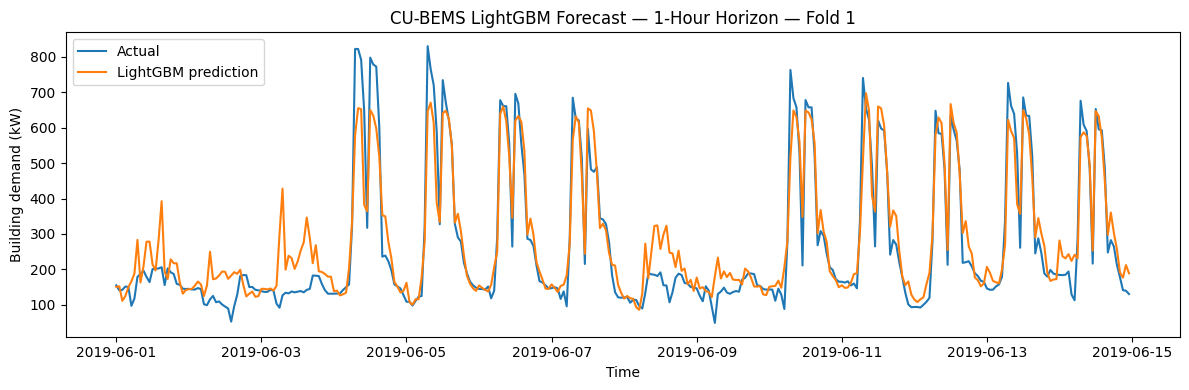

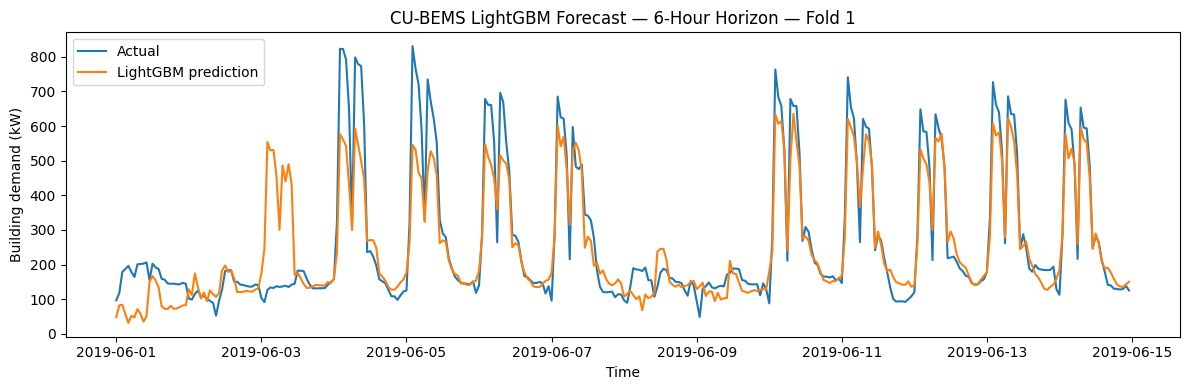

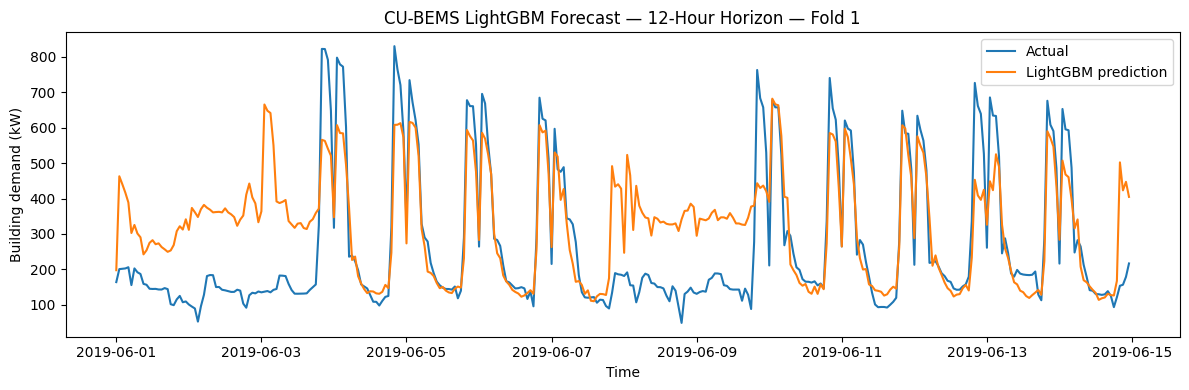

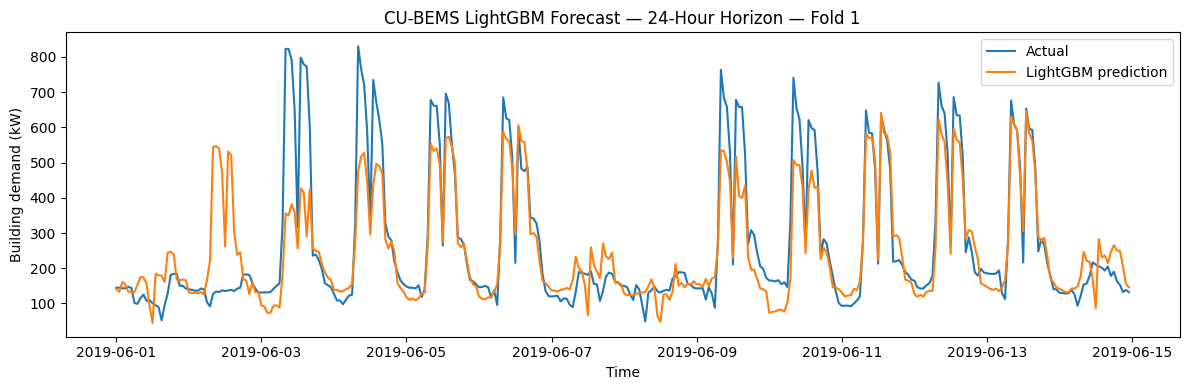

In [28]:
for h in HORIZONS:
    subset = predictions_df[
        (predictions_df["Model"] == "LightGBM") &
        (predictions_df["Horizon"] == h) &
        (predictions_df["Fold"] == 1)
    ].copy()

    if subset.empty:
        continue

    plt.figure(figsize=(12, 4))
    plt.plot(subset["Date"], subset["Actual"], label="Actual")
    plt.plot(subset["Date"], subset["Predicted"], label="LightGBM prediction")
    plt.xlabel("Time")
    plt.ylabel("Building demand (kW)")
    plt.title(f"CU-BEMS LightGBM Forecast — {h}-Hour Horizon — Fold 1")
    plt.legend()
    plt.tight_layout()
    plt.show()

## 18. Model comparison visualisation

Lower MAE/RMSE is better, while higher R² is better.

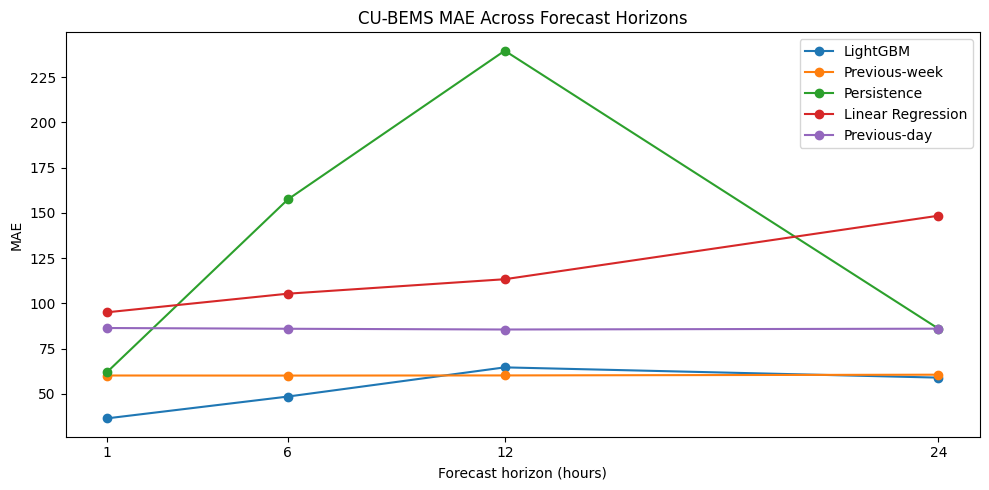

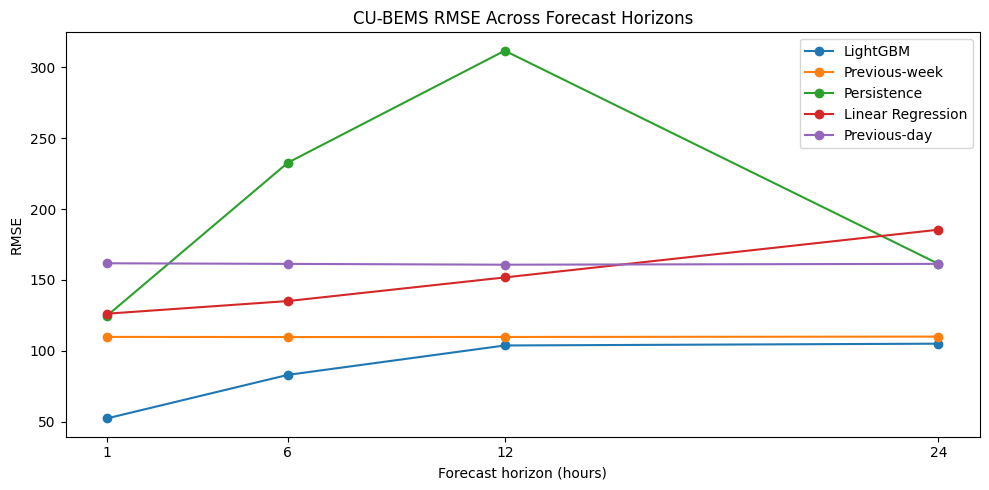

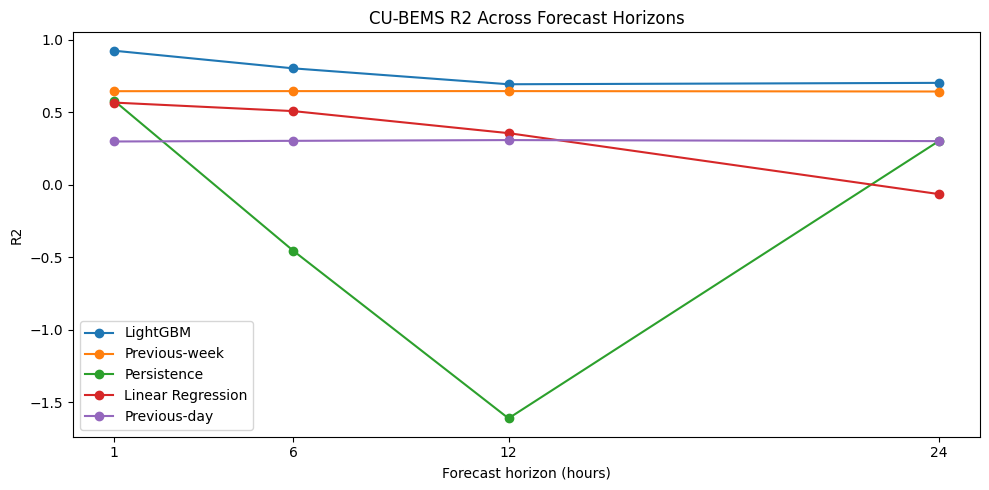

In [29]:
for metric in ["MAE", "RMSE", "R2"]:
    plt.figure(figsize=(10, 5))

    for model in summary_results["Model"].unique():
        subset = summary_results[
            summary_results["Model"] == model
        ].sort_values("Horizon")

        plt.plot(
            subset["Horizon"],
            subset[metric],
            marker="o",
            label=model
        )

    plt.xlabel("Forecast horizon (hours)")
    plt.ylabel(metric)
    plt.title(f"CU-BEMS {metric} Across Forecast Horizons")
    plt.xticks(HORIZONS)
    plt.legend()
    plt.tight_layout()
    plt.show()

## 19. Seasonal baseline skill

To determine whether machine-learning models provide meaningful improvement over simple forecasting strategies, we compare LightGBM against the **best seasonal baseline** at each horizon.

Skill is calculated as:

`Skill (%) = (Baseline RMSE − Model RMSE) / Baseline RMSE × 100`

Positive skill means the model improves on the baseline.

In [30]:
skill_rows = []

for h in HORIZONS:
    horizon_summary = summary_results[
        summary_results["Horizon"] == h
    ].copy()

    seasonal = horizon_summary[
        horizon_summary["Model"].isin(
            ["Persistence", "Previous-day", "Previous-week"]
        )
    ]

    if seasonal.empty:
        continue

    best_baseline_row = seasonal.loc[
        seasonal["RMSE"].idxmin()
    ]

    best_baseline = best_baseline_row["Model"]
    baseline_rmse = best_baseline_row["RMSE"]

    for _, row in horizon_summary.iterrows():
        skill = (
            (baseline_rmse - row["RMSE"]) /
            baseline_rmse * 100
        )

        skill_rows.append({
            "Horizon": h,
            "Model": row["Model"],
            "Best seasonal baseline": best_baseline,
            "Baseline RMSE": baseline_rmse,
            "Model RMSE": row["RMSE"],
            "Skill vs best seasonal baseline (%)": skill
        })

skill_df = pd.DataFrame(skill_rows)
display(skill_df.round(3))

,Horizon,Model,Best seasonal baseline,Baseline RMSE,Model RMSE,Skill vs best seasonal baseline (%)
0,1,LightGBM,Previous-week,109.8230,52.3550,52.3280
1,1,Previous-week,Previous-week,109.8230,109.8230,0.0000
2,1,Persistence,Previous-week,109.8230,124.8850,-13.7150
3,1,Linear Regression,Previous-week,109.8230,126.2110,-14.9220
4,1,Previous-day,Previous-week,109.8230,161.7610,-47.2920
5,6,LightGBM,Previous-week,109.7150,83.0280,24.3240
6,6,Previous-week,Previous-week,109.7150,109.7150,0.0000
7,6,Linear Regression,Previous-week,109.7150,135.1110,-23.1480
8,6,Previous-day,Previous-week,109.7150,161.3370,-47.0520
9,6,Persistence,Previous-week,109.7150,232.7620,-112.1520


## 20. Save reproducible results

The saved files are designed to match the structure used by the supporting Dataset 2 and Dataset 3 notebooks.

- `d1_results_by_fold.csv` — model × horizon × fold results
- `d1_summary.csv` — main comparison table
- `d1_peak_results.csv` — peak-demand results
- `d1_predictions.csv` — prediction-level results
- `d1_settings.txt` — key preprocessing and validation settings

In [31]:
processed_dir = folder / "processed"
processed_dir.mkdir(exist_ok=True)

results_by_fold.to_csv(
    processed_dir / "d1_results_by_fold.csv",
    index=False
)

summary_results.to_csv(
    processed_dir / "d1_summary.csv",
    index=False
)

peak_summary.to_csv(
    processed_dir / "d1_peak_results.csv",
    index=False
)

predictions_df.to_csv(
    processed_dir / "d1_predictions.csv",
    index=False
)

settings = {
    "Dataset": "CU-BEMS",
    "Main modelling year": "2019",
    "Minimum valid minute observations per hour": MIN_VALID_MINUTES_PER_HOUR,
    "Forecast horizons (hours)": HORIZONS,
    "Rolling-origin folds": N_FOLDS,
    "Test fold length (days)": FOLD_LENGTH_DAYS,
    "First test fold": str(FOLD_START.date()),
    "Models": [
        "Persistence",
        "Previous-day",
        "Previous-week",
        "Linear Regression",
        "LightGBM"
    ],
    "LightGBM": {
        "n_estimators": 600,
        "learning_rate": 0.03,
        "num_leaves": 31,
        "random_state": RANDOM_SEED
    },
    "Target missing values": "Never replaced with zero",
    "Environmental features": "Current-time values only; future t+h values excluded",
    "Validation": "Chronological rolling-origin"
}

with open(processed_dir / "d1_settings.txt", "w", encoding="utf-8") as f:
    f.write(json.dumps(settings, indent=2))

print("Saved results to:", processed_dir.resolve())

Saved results to: /Users/daki/Desktop/SEM 2/CP/Project/Project/Dataset/CU-Beams/processed


# 21. Final CU-BEMS Summary

The results show that LightGBM performs best across all four forecasting horizons (1, 6, 12, and 24 hours), achieving the lowest reported prediction errors. Compared with the strongest seasonal baseline, Previous-week, LightGBM improves RMSE by 52.33% at 1 hour, 24.32% at 6 hours, 5.47% at 12 hours, and 4.53% at 24 hours. However, prediction error generally increases as the forecasting horizon becomes longer, while the advantage of LightGBM over the seasonal baseline decreases. Although a rolling-origin evaluation framework was used, performance stability across folds cannot be reliably assessed because most evaluation folds contain no valid target observations, with only five valid observations available in Fold 5. Similarly, a reliable comparison of peak-demand performance with overall performance could not be made because there were insufficient valid peak-demand observations. A major limitation of the CU-BEMS dataset is the substantial amount of missing target information: 4,409 of 8,747 hourly observations (50.41%) have missing building-demand targets because of insufficient sensor coverage. Overall, LightGBM is the strongest forecasting approach for the available CU-BEMS data, particularly for short-term forecasting, but the high level of missing target data limits the reliability of longer-horizon, peak-demand, and rolling-origin evaluation results.

## Peak-Demand Reliability Analysis

In [32]:
# ---------------------------------------------------------
# Peak-demand analysis: identify peak observations
# ---------------------------------------------------------

peak_predictions = []

for h in HORIZONS:
    for fold_info in folds:
        fold = fold_info["fold"]
        test_start = fold_info["test_start"]
        test_end = fold_info["test_end"]

        # Training data must end before the test period
        train_mask = (
            (model_data["Date"] + pd.Timedelta(hours=h)) < test_start
        )

        train_targets = model_data.loc[
            train_mask, f"target_{h}h"
        ].dropna()

        # Skip folds without enough training target data
        if train_targets.empty:
            continue

        # Peak = top 10% of demand in the training data
        peak_threshold = train_targets.quantile(0.90)

        # Select predictions for this horizon and fold
        subset = predictions_df[
            (predictions_df["Horizon"] == h) &
            (predictions_df["Fold"] == fold)
        ].copy()

        if subset.empty:
            continue

        # Mark actual peak-demand observations
        subset["Peak"] = subset["Actual"] >= peak_threshold
        subset["Peak threshold"] = peak_threshold

        peak_predictions.append(subset)

if peak_predictions:
    peak_predictions = pd.concat(
        peak_predictions, ignore_index=True
    )

    print("Peak-demand observations identified.")
    print("Total observations:", len(peak_predictions))
    print("Peak observations:", peak_predictions["Peak"].sum())
else:
    print("No valid peak-demand observations were available.")

Peak-demand observations identified.
Total observations: 40200
Peak observations: 4925


In [33]:
# ---------------------------------------------------------
# Compare model performance during peak-demand periods
# ---------------------------------------------------------

peak_summary = []

for (model, horizon), group in peak_predictions.groupby(["Model", "Horizon"]):

    peak_group = group[group["Peak"]]

    if len(peak_group) == 0:
        continue

    metrics = regression_metrics(
        peak_group["Actual"],
        peak_group["Predicted"]
    )

    peak_summary.append({
        "Model": model,
        "Horizon": horizon,
        "n": len(peak_group),
        **metrics
    })

peak_summary = pd.DataFrame(peak_summary)

display(
    peak_summary
    .sort_values(["Horizon", "RMSE"])
    .round(3)
)

,Model,Horizon,n,MAE,RMSE,R2,nMAE (%),CV(RMSE) (%)
0,LightGBM,1,247,45.1000,63.5880,-0.4230,6.8120,9.6050
4,Linear Regression,1,247,163.6550,190.4850,-11.7740,24.7190,28.7720
16,Previous-week,1,247,119.3360,208.2040,-14.2610,18.0250,31.4480
8,Persistence,1,247,200.8200,283.7670,-27.3480,30.3330,42.8610
12,Previous-day,1,247,206.2850,323.6060,-35.8670,31.1580,48.8790
1,LightGBM,6,247,71.9560,105.2610,-2.9010,10.8690,15.8990
5,Linear Regression,6,247,171.3980,190.6530,-11.7960,25.8890,28.7970
17,Previous-week,6,247,119.3360,208.2040,-14.2610,18.0250,31.4480
13,Previous-day,6,247,206.2850,323.6060,-35.8670,31.1580,48.8790
9,Persistence,6,247,384.6600,440.4610,-67.2990,58.1010,66.5290


### Peak-demand findings

The peak-demand analysis shows that LightGBM provides the strongest forecasting performance across all four forecasting horizons. Its RMSE increases from 63.59 at the 1-hour horizon to 171.61 at the 24-hour horizon, indicating that forecasting peak demand becomes more difficult as the prediction horizon increases. However, LightGBM consistently outperforms the Previous-week baseline, which is the strongest seasonal baseline in this experiment. This suggests that the machine-learning model is particularly useful for identifying and forecasting periods of high building electricity demand.

In [34]:
# ============================================================2
# Step 1 — Inspect real missing-sensor outage patterns
# ============================================================

def get_missing_run_lengths(series):
    """
    Return lengths of consecutive missing-value runs.
    The data are sampled every minute.
    """
    missing = series.isna().to_numpy()

    run_lengths = []
    current_run = 0

    for value in missing:
        if value:
            current_run += 1
        else:
            if current_run > 0:
                run_lengths.append(current_run)
                current_run = 0

    if current_run > 0:
        run_lengths.append(current_run)

    return run_lengths


missing_pattern_rows = []

for file in files:

    # We only need the 2019 CU-BEMS data used in the main experiment
    if not file.name.startswith("2019"):
        continue

    temp = pd.read_csv(file)

    power_cols, temp_cols, rh_cols, lux_cols = identify_columns(temp)

    sensor_groups = {
        "Electricity": power_cols,
        "Temperature": temp_cols,
        "Humidity": rh_cols,
        "Illuminance": lux_cols
    }

    for sensor_type, cols in sensor_groups.items():

        for col in cols:

            missing_count = int(temp[col].isna().sum())
            missing_pct = temp[col].isna().mean() * 100

            if missing_count > 0:
                runs = get_missing_run_lengths(temp[col])

                missing_pattern_rows.append({
                    "File": file.name,
                    "Sensor type": sensor_type,
                    "Sensor": col,
                    "Missing %": missing_pct,
                    "Missing observations": missing_count,
                    "Number of missing runs": len(runs),
                    "Median outage (minutes)": np.median(runs),
                    "Mean outage (minutes)": np.mean(runs),
                    "Maximum outage (minutes)": np.max(runs)
                })


missing_patterns_df = pd.DataFrame(missing_pattern_rows)

print("Actual missing-sensor patterns in CU-BEMS 2019:")
display(
    missing_patterns_df
    .sort_values("Missing %", ascending=False)
    .round(2)
)

print("\nSummary by sensor type:")

display(
    missing_patterns_df
    .groupby("Sensor type")
    .agg(
        Sensors=("Sensor", "count"),
        Mean_missing_pct=("Missing %", "mean"),
        Median_outage_min=("Median outage (minutes)", "median"),
        Mean_outage_min=("Mean outage (minutes)", "mean"),
        Max_outage_min=("Maximum outage (minutes)", "max")
    )
    .round(2)
)

Actual missing-sensor patterns in CU-BEMS 2019:


,File,Sensor type,Sensor,Missing %,Missing observations,Number of missing runs,Median outage (minutes),Mean outage (minutes),Maximum outage (minutes)
123,2019Floor5.csv,Temperature,z2_S1(degC),42.5700,223773,595,2.0000,376.0900,99760
131,2019Floor5.csv,Illuminance,z2_S1(lux),42.5700,223773,595,2.0000,376.0900,99760
127,2019Floor5.csv,Humidity,z2_S1(RH%),42.5700,223773,595,2.0000,376.0900,99760
95,2019Floor4.csv,Temperature,z4_S1(degC),35.0800,184370,695,2.0000,265.2800,93008
99,2019Floor4.csv,Humidity,z4_S1(RH%),35.0800,184370,695,2.0000,265.2800,93008
...,...,...,...,...,...,...,...,...,...
8,2019Floor1.csv,Electricity,z3_Light(kW),0.1100,599,13,19.0000,46.0800,269
57,2019Floor3.csv,Electricity,z3_Plug(kW),0.1100,587,28,3.0000,20.9600,255
55,2019Floor3.csv,Electricity,z2_Plug(kW),0.1100,586,44,1.0000,13.3200,249
52,2019Floor3.csv,Electricity,z1_Plug(kW),0.1100,555,26,4.0000,21.3500,249



Summary by sensor type:


,Sensors,Mean_missing_pct,Median_outage_min,Mean_outage_min,Max_outage_min
Sensor type,,,,,
Electricity,120,1.9500,1.0000,71.0400,89391
Humidity,24,23.7900,2.0000,183.8800,99760
Illuminance,24,23.7900,2.0000,183.8500,99760
Temperature,24,23.7900,2.0000,183.9900,99760


In [35]:
# ============================================================
# PROFESSOR FEEDBACK 1: HOW MUCH DOES MISSING SENSOR DATA
# HARM THE MODEL?
# ============================================================

# Identify missing input information at the forecasting origin
env_cols = ["temperature", "humidity", "lux"]

demand_history_cols = [
    "lag_1h", "lag_2h", "lag_3h", "lag_6h",
    "lag_12h", "lag_24h", "lag_48h", "lag_168h",
    "rolling_mean_24h", "rolling_std_24h",
    "rolling_min_24h", "rolling_max_24h",
    "rolling_mean_168h", "rolling_std_168h",
    "rolling_min_168h", "rolling_max_168h"
]

# Flag whether environmental sensor information is missing
model_data["Environment_missing"] = (
    model_data[env_cols].isna().any(axis=1)
)

# Flag whether recent demand-history information is missing
model_data["Demand_history_missing"] = (
    model_data[demand_history_cols].isna().any(axis=1)
)

# Merge the missing-information flags with predictions
missing_analysis = predictions_df.merge(
    model_data[
        [
            "Date",
            "Environment_missing",
            "Demand_history_missing"
        ]
    ],
    on="Date",
    how="left"
)

# ------------------------------------------------------------
# 1. Environmental sensor missingness
# ------------------------------------------------------------

env_rows = []

for (model, horizon), group in missing_analysis.groupby(
    ["Model", "Horizon"]
):

    complete = group[
        ~group["Environment_missing"]
    ]

    missing = group[
        group["Environment_missing"]
    ]

    if len(complete) > 0 and len(missing) > 0:

        complete_metrics = regression_metrics(
            complete["Actual"],
            complete["Predicted"]
        )

        missing_metrics = regression_metrics(
            missing["Actual"],
            missing["Predicted"]
        )

        rmse_change = (
            (missing_metrics["RMSE"] - complete_metrics["RMSE"])
            / complete_metrics["RMSE"] * 100
        )

        mae_change = (
            (missing_metrics["MAE"] - complete_metrics["MAE"])
            / complete_metrics["MAE"] * 100
        )

        env_rows.append({
            "Model": model,
            "Horizon": horizon,
            "Complete n": len(complete),
            "Missing n": len(missing),
            "Complete RMSE": complete_metrics["RMSE"],
            "Missing RMSE": missing_metrics["RMSE"],
            "RMSE change (%)": rmse_change,
            "Complete MAE": complete_metrics["MAE"],
            "Missing MAE": missing_metrics["MAE"],
            "MAE change (%)": mae_change
        })

# Keep the schema even when no forecast group contains both categories.
# An empty table is a valid finding, not a training failure.
missingness_columns = [
    "Model", "Horizon", "Complete n", "Missing n",
    "Complete RMSE", "Missing RMSE", "RMSE change (%)",
    "Complete MAE", "Missing MAE", "MAE change (%)"
]
env_missing_results = pd.DataFrame(env_rows, columns=missingness_columns)

print("ENVIRONMENTAL SENSOR MISSINGNESS")
if env_missing_results.empty:
    print("No comparable complete/missing environmental groups in evaluation predictions.")
else:
    display(env_missing_results.sort_values(["Horizon", "Model"]).round(3))


# ------------------------------------------------------------
# 2. Recent demand-history missingness
# ------------------------------------------------------------

demand_rows = []

for (model, horizon), group in missing_analysis.groupby(
    ["Model", "Horizon"]
):

    complete = group[
        ~group["Demand_history_missing"]
    ]

    missing = group[
        group["Demand_history_missing"]
    ]

    if len(complete) > 0 and len(missing) > 0:

        complete_metrics = regression_metrics(
            complete["Actual"],
            complete["Predicted"]
        )

        missing_metrics = regression_metrics(
            missing["Actual"],
            missing["Predicted"]
        )

        rmse_change = (
            (missing_metrics["RMSE"] - complete_metrics["RMSE"])
            / complete_metrics["RMSE"] * 100
        )

        mae_change = (
            (missing_metrics["MAE"] - complete_metrics["MAE"])
            / complete_metrics["MAE"] * 100
        )

        demand_rows.append({
            "Model": model,
            "Horizon": horizon,
            "Complete n": len(complete),
            "Missing n": len(missing),
            "Complete RMSE": complete_metrics["RMSE"],
            "Missing RMSE": missing_metrics["RMSE"],
            "RMSE change (%)": rmse_change,
            "Complete MAE": complete_metrics["MAE"],
            "Missing MAE": missing_metrics["MAE"],
            "MAE change (%)": mae_change
        })

demand_missing_results = pd.DataFrame(demand_rows, columns=missingness_columns)

print("\nRECENT DEMAND-HISTORY MISSINGNESS")
if demand_missing_results.empty:
    print("No comparable complete/missing demand-history groups in evaluation predictions.")
else:
    display(demand_missing_results.sort_values(["Horizon", "Model"]).round(3))


# ------------------------------------------------------------
# 3. LightGBM summary — easiest table for the report
# ------------------------------------------------------------

lgbm_env = env_missing_results[
    env_missing_results["Model"] == "LightGBM"
].copy()

lgbm_demand = demand_missing_results[
    demand_missing_results["Model"] == "LightGBM"
].copy()

print("\nLIGHTGBM — ENVIRONMENTAL SENSOR MISSINGNESS")
if lgbm_env.empty:
    print("Not available: both missing and complete groups are required.")
else:
    display(lgbm_env.round(3))

print("\nLIGHTGBM — RECENT DEMAND-HISTORY MISSINGNESS")
if lgbm_demand.empty:
    print("Not available: both missing and complete groups are required.")
else:
    display(lgbm_demand.round(3))

print("\nINPUT AVAILABILITY (evaluation predictions)")
for name in ["Environment_missing", "Demand_history_missing"]:
    print(name)
    display(missing_analysis[name].value_counts(dropna=False).rename_axis("Missing?").to_frame("Observations"))

ENVIRONMENTAL SENSOR MISSINGNESS
No comparable complete/missing environmental groups in evaluation predictions.

RECENT DEMAND-HISTORY MISSINGNESS


,Model,Horizon,Complete n,Missing n,Complete RMSE,Missing RMSE,RMSE change (%),Complete MAE,Missing MAE,MAE change (%)
0,LightGBM,1,1949,61,52.5820,77.2550,46.9220,35.8820,53.3130,48.5780
4,Linear Regression,1,1949,61,128.5920,113.0800,-12.0630,95.1270,93.1390,-2.0900
8,Persistence,1,1949,61,126.7900,21.8150,-82.7950,63.5780,14.0930,-77.8330
12,Previous-day,1,1949,61,163.6260,165.0430,0.8660,85.9320,95.1850,10.7690
16,Previous-week,1,1949,61,117.3920,580.7080,394.6750,59.5750,580.7080,874.7500
1,LightGBM,6,1949,61,84.5770,147.0890,73.9120,46.9710,95.4540,103.2170
5,Linear Regression,6,1949,61,136.2490,161.3190,18.4000,104.7280,124.1670,18.5610
9,Persistence,6,1949,61,236.4460,41.1680,-82.5890,161.3790,32.8540,-79.6420
13,Previous-day,6,1949,61,163.0480,165.1510,1.2900,85.5310,94.9060,10.9610
17,Previous-week,6,1949,61,115.4670,452.2070,291.6340,58.7300,419.0050,613.4440



LIGHTGBM — ENVIRONMENTAL SENSOR MISSINGNESS
Not available: both missing and complete groups are required.

LIGHTGBM — RECENT DEMAND-HISTORY MISSINGNESS


,Model,Horizon,Complete n,Missing n,Complete RMSE,Missing RMSE,RMSE change (%),Complete MAE,Missing MAE,MAE change (%)
0,LightGBM,1,1949,61,52.5820,77.2550,46.9220,35.8820,53.3130,48.5780
1,LightGBM,6,1949,61,84.5770,147.0890,73.9120,46.9710,95.4540,103.2170
2,LightGBM,12,1949,61,102.6370,233.6910,127.6860,59.9400,214.1050,257.1990
3,LightGBM,24,1949,61,103.8820,172.9810,66.5180,57.4270,105.9010,84.4120



INPUT AVAILABILITY (evaluation predictions)
Environment_missing


,Observations
Missing?,
False,40200


Demand_history_missing


,Observations
Missing?,
False,38980
True,1220


## 22. Holiday feature experiment (CU-BEMS, 2019)

**Research question:** Does a known-in-advance Thai public-holiday indicator improve the 1h, 6h, 12h, and 24h LightGBM forecasts?

We compare **the same model and folds** with and without a single additional holiday feature. The holiday indicator refers to the **forecast target time** (`t + h`), not just the forecast origin (`t`). A calendar is known in advance, so this is not target leakage. Public holidays are a proxy for changed activity; **university-specific shutdowns and special academic dates are not necessarily captured**. This experiment does not overwrite the main model/results.


In [36]:
%pip install -q holidays


You should consider upgrading via the '/Users/daki/Desktop/SEM 2/CP/Project/Project/.venv/bin/python -m pip install --upgrade pip' command.
Note: you may need to restart the kernel to use updated packages.


In [37]:
# Holiday dictionary for Thailand (2019)
import holidays as holiday_library

thai_holidays = holiday_library.country_holidays("TH", years=[2019])

# Inspect the known holiday dates (verify if they reflect CU-BEMS campus operations)
holiday_calendar = pd.DataFrame([
    {"Date": pd.Timestamp(day), "Holiday": name}
    for day, name in sorted(thai_holidays.items())
])
print("Thai public holiday dates in 2019:")
display(holiday_calendar)

# Use actual dataset timestamps, and do NOT replace the original feature set
holiday_model_data = model_data.copy()
holiday_feature_cols = feature_cols + ["target_is_holiday"]
assert "target_is_holiday" not in feature_cols

# Add one target-specific holiday indicator for each forecast horizon
for h in HORIZONS:
    forecast_target_dates = holiday_model_data["Date"] + pd.Timedelta(hours=h)
    holiday_model_data[f"target_is_holiday_{h}h"] = (
        forecast_target_dates.dt.date.map(lambda day: int(day in thai_holidays))
    ).astype(int)

print("Holiday indicator columns created:")
display(holiday_model_data[["Date"] + [f"target_is_holiday_{h}h" for h in HORIZONS]].head())


Thai public holiday dates in 2019:


,Date,Holiday
0,2019-01-01,New Year's Day
1,2019-01-12,National Children's Day
2,2019-02-19,Makha Bucha
3,2019-04-06,Chakri Memorial Day
4,2019-04-08,Chakri Memorial Day (in lieu)
5,2019-04-13,Songkran Festival
6,2019-04-14,Songkran Festival
7,2019-04-15,Songkran Festival
8,2019-04-16,Songkran Festival (in lieu)
9,2019-05-01,National Labor Day


Holiday indicator columns created:


,Date,target_is_holiday_1h,target_is_holiday_6h,target_is_holiday_12h,target_is_holiday_24h
0,2019-01-01 00:00:00,1,1,1,0
1,2019-01-01 01:00:00,1,1,1,0
2,2019-01-01 02:00:00,1,1,1,0
3,2019-01-01 03:00:00,1,1,1,0
4,2019-01-01 04:00:00,1,1,1,0


In [38]:
# Paired holiday-feature ablation: LightGBM, exactly the original 6 rolling folds
holiday_ablation_rows = []
holiday_ablation_predictions = []

for h in HORIZONS:
    target_col = f"target_{h}h"
    holiday_col = f"target_is_holiday_{h}h"

    for fold_info in folds:
        fold = fold_info["fold"]
        test_start = fold_info["test_start"]
        test_end = fold_info["test_end"]

        # Replicate the ORIGINAL training/test split and target filtering
        train_mask = (holiday_model_data["Date"] + pd.Timedelta(hours=h)) < test_start
        test_mask = (holiday_model_data["Date"] >= test_start) & (holiday_model_data["Date"] < test_end)
        train = holiday_model_data.loc[train_mask].dropna(subset=[target_col]).copy()
        test = holiday_model_data.loc[test_mask].dropna(subset=[target_col]).copy()

        if train.empty or test.empty:
            print(f"Skipped {h}h fold {fold}: no valid train/test target")
            continue

        y_train = train[target_col]
        y_test = test[target_col]

        # Keep both conditions on identical observations
        conditions = {
            "Without holiday": list(feature_cols),
            "With holiday": list(feature_cols) + [holiday_col]
        }
        for label, columns in conditions.items():
            model = make_lgbm()
            model.fit(train[columns], y_train)
            pred = model.predict(test[columns])
            metrics = regression_metrics(y_test, pred)

            holiday_ablation_rows.append({
                "Horizon": h, "Fold": fold, "Condition": label,
                "Test observations": len(test),
                "Holiday test observations": int(test[holiday_col].sum()),
                "MAE": metrics["MAE"], "RMSE": metrics["RMSE"], "R2": metrics["R2"]
            })
            holiday_ablation_predictions.append(pd.DataFrame({
                "Date": test["Date"].to_numpy(),
                "Horizon": h, "Fold": fold, "Condition": label,
                "Actual": y_test.to_numpy(), "Predicted": pred,
                "Target holiday": test[holiday_col].to_numpy()
            }))

holiday_ablation_folds = pd.DataFrame(holiday_ablation_rows)
if holiday_ablation_folds.empty:
    print("No valid folds. Check the dataset and validation dates.")
else:
    print("Per-fold holiday results:")
    display(holiday_ablation_folds.round(3))


Per-fold holiday results:


,Horizon,Fold,Condition,Test observations,Holiday test observations,MAE,RMSE,R2
0,1,1,Without holiday,336,24,48.6450,69.9560,0.8770
1,1,1,With holiday,336,24,46.9150,67.0920,0.8870
2,1,2,Without holiday,336,0,31.7190,49.1670,0.9390
3,1,2,With holiday,336,0,31.6400,49.1810,0.9390
4,1,3,Without holiday,334,0,38.6530,58.6570,0.8910
5,1,3,With holiday,334,0,38.2530,58.3120,0.8920
6,1,4,Without holiday,332,48,39.9480,56.5230,0.9270
7,1,4,With holiday,332,48,38.9300,55.0830,0.9310
8,1,5,Without holiday,336,48,32.8480,44.7750,0.9420
9,1,5,With holiday,336,48,32.2790,43.9280,0.9440


Holiday feature comparison (negative change = improvement):


,Horizon,MAE - With holiday,MAE - Without holiday,RMSE - With holiday,RMSE - Without holiday,RMSE change (%),MAE change (%)
0,1,35.6450,36.4110,52.3450,53.4990,-2.1560,-2.1050
1,6,33.8260,48.4430,45.2270,87.1360,-48.0960,-30.1740
2,12,57.6770,64.6190,92.7550,108.9590,-14.8720,-10.7430
3,24,53.2290,58.8980,90.2440,106.6400,-15.3750,-9.6240


Number of holiday observations in validation (per horizon; unique dates):


,sum,count
Horizon,,
1,144,2010
6,144,2010
12,144,2010
24,144,2010


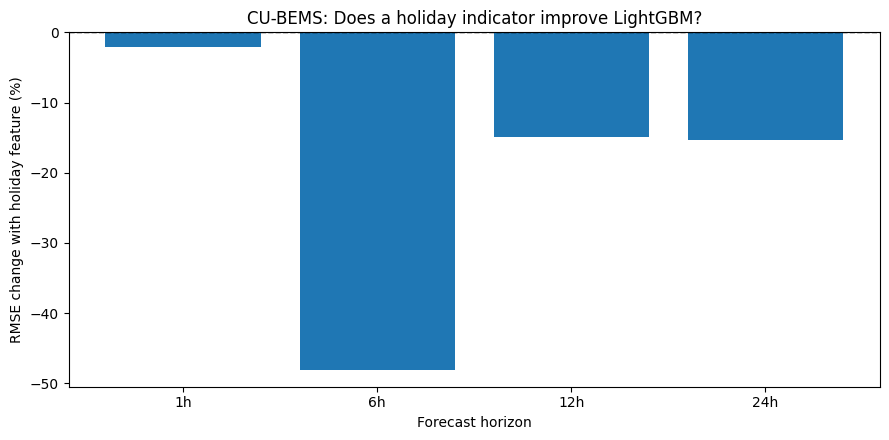

Saved d1_holiday_by_fold.csv and d1_holiday_comparison.csv


In [39]:
# Aggregate results using all same-date predictions from available test folds
if holiday_ablation_predictions:
    holiday_pred_df = pd.concat(holiday_ablation_predictions, ignore_index=True)
    pooled_rows = []
    for (h, condition), group in holiday_pred_df.groupby(["Horizon", "Condition"]):
        m = regression_metrics(group["Actual"], group["Predicted"])
        pooled_rows.append({"Horizon": h, "Condition": condition,
                            "n": m["n"], "MAE": m["MAE"], "RMSE": m["RMSE"], "R2": m["R2"]})
    holiday_summary = pd.DataFrame(pooled_rows)
    holiday_comparison = holiday_summary.pivot(index="Horizon", columns="Condition", values=["MAE", "RMSE"])
    holiday_comparison.columns = [f"{metric} - {condition}" for metric, condition in holiday_comparison.columns]
    holiday_comparison = holiday_comparison.reset_index()
    holiday_comparison["RMSE change (%)"] = (
        (holiday_comparison["RMSE - With holiday"] - holiday_comparison["RMSE - Without holiday"])
        / holiday_comparison["RMSE - Without holiday"] * 100
    )
    holiday_comparison["MAE change (%)"] = (
        (holiday_comparison["MAE - With holiday"] - holiday_comparison["MAE - Without holiday"])
        / holiday_comparison["MAE - Without holiday"] * 100
    )
    print("Holiday feature comparison (negative change = improvement):")
    display(holiday_comparison.round(3))

    print("Number of holiday observations in validation (per horizon; unique dates):")
    display(holiday_pred_df[holiday_pred_df["Condition"] == "Without holiday"]
            .groupby("Horizon")["Target holiday"].agg(["sum", "count"]))

    plt.figure(figsize=(9, 4.5))
    plt.bar(holiday_comparison["Horizon"].astype(str) + "h", holiday_comparison["RMSE change (%)"])
    plt.axhline(0, color="black", linestyle="--", linewidth=1)
    plt.xlabel("Forecast horizon")
    plt.ylabel("RMSE change with holiday feature (%)")
    plt.title("CU-BEMS: Does a holiday indicator improve LightGBM?")
    plt.tight_layout()
    plt.show()

    output_dir = folder / "processed"
    output_dir.mkdir(parents=True, exist_ok=True)
    holiday_ablation_folds.to_csv(output_dir / "d1_holiday_by_fold.csv", index=False)
    holiday_comparison.to_csv(output_dir / "d1_holiday_comparison.csv", index=False)
    print("Saved d1_holiday_by_fold.csv and d1_holiday_comparison.csv")
else:
    print("No predictions to compare.")


# 23. Train and export four FINAL CU-BEMS LightGBM models

**Run this section after the main dataset preparation and holiday cells.** These are final models for website use, not another validation experiment.

We train one LightGBM model for each horizon (1h, 6h, 12h, 24h), using all available *labelled* 2019 observations. The training features match the tested holiday-enhanced model: the original 24 features **plus the appropriate target-date holiday indicator**.

The training data must not include the target column as a feature. Previously measured evaluation scores come from rolling-origin validation, not this final full-data fit.

This section also saves the four trained models and metadata. It **does not** create an inference pipeline for incoming website data; that is the next deployment-preparation step.


In [40]:
# Final model training and exports — run after holiday_model_data,
# feature_cols, HORIZONS, make_lgbm and thai_holidays are defined.
import json
import joblib
import lightgbm
import sklearn
from pathlib import Path

required_names = ["holiday_model_data", "feature_cols", "HORIZONS", "make_lgbm"]
missing_names = [name for name in required_names if name not in globals()]
if missing_names:
    raise RuntimeError(
        "Run the earlier notebook cells first. Missing: " + ", ".join(missing_names)
    )

# Resolve the project root from the located data folder, not Jupyter's cwd.
# Expected: PROJECT/Dataset/CU-Beams
project_root = folder.parent.parent
models_dir = project_root / "models"
models_dir.mkdir(parents=True, exist_ok=True)
print("Final models directory:", models_dir.resolve())

final_models = {}
final_model_rows = []
final_metadata = {
    "dataset": "CU-BEMS",
    "training_period": "2019",
    "model_type": "LightGBM",
    "forecast_target": "building_demand (kW)",
    "forecast_horizons_hours": list(HORIZONS),
    "features_original": list(feature_cols),
    "holiday_country": "TH",
    "holiday_feature_rule": "Indicator for the forecast TARGET date: origin timestamp + horizon hours",
    "target_rule": "target_{h}h from existing notebook (shift -h)",
    "missing_inputs": "LightGBM native NaN handling; preserve original feature generation",
    "package_versions": {
        "lightgbm": lightgbm.__version__,
        "sklearn": sklearn.__version__,
    },
    "models": {},
}

for h in HORIZONS:
    target = f"target_{h}h"
    holiday_feature = f"target_is_holiday_{h}h"
    columns = list(feature_cols) + [holiday_feature]

    absent = [c for c in columns + [target, "Date"] if c not in holiday_model_data.columns]
    if absent:
        raise ValueError(f"{h}h: Missing required columns: {absent}")

    # Use only rows whose future demand is actually observed.
    training = holiday_model_data.dropna(subset=[target]).sort_values("Date").copy()
    if training.empty:
        raise ValueError(f"No valid training targets available for {h}h")

    X_train = training[columns]
    y_train = training[target]

    model = make_lgbm()  # Identical hyperparameters to the evaluated model
    model.fit(X_train, y_train)

    # Save as a standalone trained model, no notebook state required for loading
    model_path = models_dir / f"lightgbm_{h}h.joblib"
    joblib.dump(model, model_path)
    final_models[h] = model

    final_model_rows.append({
        "Horizon (h)": h,
        "Training rows": len(training),
        "Training start": str(training["Date"].min()),
        "Last forecast origin in training": str(training["Date"].max()),
        "Feature count": len(columns),
        "Holiday-flagged training rows": int(training[holiday_feature].sum()),
        "Saved model": str(model_path),
    })

    final_metadata["models"][str(h)] = {
        "filename": model_path.name,
        "features_in_order": columns,
        "training_rows": int(len(training)),
        "training_start": str(training["Date"].min()),
        "last_training_origin": str(training["Date"].max()),
    }

metadata_path = models_dir / "model_metadata.json"
metadata_path.write_text(json.dumps(final_metadata, indent=2), encoding="utf-8")

final_training_summary = pd.DataFrame(final_model_rows)
print("FINAL CU-BEMS MODEL TRAINING COMPLETE")
display(final_training_summary)
print("Metadata saved to:", metadata_path)


Final models directory: /Users/daki/Desktop/SEM 2/CP/Project/Project/models
FINAL CU-BEMS MODEL TRAINING COMPLETE


,Horizon (h),Training rows,Training start,Last forecast origin in training,Feature count,Holiday-flagged training rows,Saved model
0,1,4337,2019-01-01 00:00:00,2019-10-22 11:00:00,25,259,/Users/daki/Desktop/SEM 2/CP/Project/Project/m...
1,6,4332,2019-01-01 00:00:00,2019-10-22 06:00:00,25,254,/Users/daki/Desktop/SEM 2/CP/Project/Project/m...
2,12,4326,2019-01-01 00:00:00,2019-10-22 00:00:00,25,248,/Users/daki/Desktop/SEM 2/CP/Project/Project/m...
3,24,4314,2019-01-01 00:00:00,2019-10-21 12:00:00,25,240,/Users/daki/Desktop/SEM 2/CP/Project/Project/m...


Metadata saved to: /Users/daki/Desktop/SEM 2/CP/Project/Project/models/model_metadata.json


## 23.1 Reload test — verify exported models

This confirms the four files exist and a fresh model object can load and predict on a known row. It is **not** a held-out accuracy evaluation. Do not present these predictions as fresh forecasts of unseen dates.


In [41]:
# Verify each model can be reloaded and predict with the expected features.
reload_checks = []
for h in HORIZONS:
    model_path = models_dir / f"lightgbm_{h}h.joblib"
    loaded = joblib.load(model_path)
    cols = final_metadata["models"][str(h)]["features_in_order"]

    valid_inputs = holiday_model_data.dropna(subset=[f"target_{h}h"])
    sample = valid_inputs[cols].tail(1)
    if sample.empty:
        raise RuntimeError(f"{h}h: no sample row available")

    prediction = float(loaded.predict(sample)[0])
    if not np.isfinite(prediction):
        raise RuntimeError(f"{h}h: exported model produced a non-finite prediction")

    reload_checks.append({
        "Horizon": f"{h}h",
        "File exists": model_path.exists(),
        "Expected feature count": len(cols),
        "Loaded successfully": True,
        "Sample prediction (kW)": prediction,
    })
reload_test_results = pd.DataFrame(reload_checks)
display(reload_test_results)
print("All four model files loaded successfully.")


,Horizon,File exists,Expected feature count,Loaded successfully,Sample prediction (kW)
0,1h,True,25,True,237.3789
1,6h,True,25,True,237.3750
2,12h,True,25,True,227.8144
3,24h,True,25,True,230.0717


All four model files loaded successfully.


In [42]:
# Export training notebook data for comparison
from pathlib import Path

output = Path("cu_bems_training_reference.csv")

model_data.to_csv(output, index=False)

print("Reference file saved:", output.resolve())
print("Total rows:", len(model_data))
print("Missing demand values:", model_data["building_demand"].isna().sum())

Reference file saved: /Users/daki/Desktop/SEM 2/CP/Project/Project/notebook/Proposal Notebook/cu_bems_training_reference.csv
Total rows: 8747
Missing demand values: 4409
